# 🧠 TensorFlow-a Giriş və Əsas Konsepsiyalar

---

Dərin öyrənməyə başlamazdan əvvəl TensorFlow-un fundamental iş prinsipini anlamaq üçün çox sadə bir misaldan başlayaq. 

### Əsas Anlayışlar:
1. **Tensor nədir?** Çoxölçülü massivdir (0D = skalyar ədəd, 1D = vektor, 2D = matris, 3D+ = çoxölçülü tensor). TensorFlow-da bütün verilənlər və çəkilər tensor şəklində saxlanılır.
2. **`tf.Variable` nədir?** Dəyəri təlim zamanı dəyişə bilən parametrdir. Neyron şəbəkəsində çəkilər ($W$) və meyil/bias ($b$) məhz `tf.Variable` olaraq təyin olunur ki, model səhvindən dərs çıxararaq onları yeniləyə bilsin.
3. **Eager Execution (Dərhal İcra):** TensorFlow 2-də hesablamalar Python kimi dərhal icra olunur (köhnə TensorFlow 1.x-dəki kimi mürəkkəb `Session` obyekti yaratmağa və qrafı ayrıca işə salmağa ehtiyac yoxdur).

Aşağıdakı kodda tək bir ədəd saxlayan iki dəyişən (`a = 1` və `b = 2`) yaradırıq və onları toplayırıq:

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.datasets import mnist

%matplotlib inline
import matplotlib.pyplot as plt

In [2]:
# 'a' və 'b' adlı iki dəyişən (skalyar tensor) yaradırıq
a = tf.Variable(1, name="a")
b = tf.Variable(2, name="b")

tf.print("a dəyişəni:", a)
tf.print("b dəyişəni:", b)

a dəyişəni: 1
b dəyişəni: 2


In [3]:
# İki tenzoru toplayırıq (TensorFlow 2 bunu dərhal hesablayır)
f = a + b

tf.print("a və b dəyişənlərinin cəmi:", f)

a və b dəyişənlərinin cəmi: 3


## ✍️ Daha Maraqlı Bir Məsələ: Əlyazma Rəqəmlərinin Tanınması (MNIST)

Maşın öyrənməsi və Dərin öyrənmə dünyasının klassik "Hello World" nümunəsi **MNIST** verilənlər bazasıdır. Bu baza 0-dan 9-a qədər əllə yazılmış **70,000** ədəd rəqəm təsvirindən ibarətdir.

Bizim məqsədimiz: Verilmiş əlyazma şəklində hansı rəqəmin yazıldığını kompüterə dəqiq tanıtdırmaqdır.

---

### 🔍 Şəkillər Kompüterə Necə Təqdim Olunur?
* Hər bir şəkil **28 × 28 piksel** ölçüsündə ağ-qara (boz çalarlı) təsvirdir.
* Bu sadə çoxqatlı perseptron (MLP) modelində biz hər şəkli **784 elementli** ($28 * 28 = 784$) 1-ölçülü (1D) vektor kimi düzləşdiririk (**Flatten**).
* Hər bir pikselin parlaqlıq dəyəri **0 ilə 255** arasındadır (0 = qara/arxa fon, 255 = ağ/rəqəmin xətləri).

### 🛠️ Verilənlərin Hazırlanması Addımları:
1. **MNIST-i Yükləmək:** TensorFlow daxilində hazır gəlir.
2. **Düzləşdirmə (Flatten):** $28 * 28$ matrisini 784 ədədlik düz vektora çevirmək.
3. **Normallaşdırma (Normalization):** Pikselləri 255-ə bölərək `[0, 1]` aralığına gətiririk. Bu, qradiyentlərin sabit qalması və modelin qat-qat sürətli öyrənməsi üçün həyati əhəmiyyət kəsb edir.

In [2]:
# MNIST verilənlər bazasının parametrləri
num_classes = 10   # Cəmi siniflərin sayı (0-9 rəqəmləri)
num_features = 784 # Giriş xüsusiyyətlərinin sayı (28 * 28 piksel)

# Təlim (train) və test dəstlərini yükləyirik
(x_train, y_train), (x_test, y_test) = mnist.load_data()

tf.print(x_train.shape)
tf.print(x_test.shape)
tf.print(y_train.shape)
tf.print(y_test.shape)

(60000, 28, 28)
(10000, 28, 28)
(60000,)
(10000,)


In [52]:
x_test[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  

In [53]:
x_test[0,7]

array([  0,   0,   0,   0,   0,   0,  84, 185, 159, 151,  60,  36,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0], dtype=uint8)

In [54]:
x_test[0,7,6]

np.uint8(84)

In [5]:
# Dəyərləri float32 tipinə çeviririk
x_train, x_test = np.array(x_train, np.float32), np.array(x_test, np.float32)

x_test[0,7,6]

np.float32(84.0)

In [6]:
# Hər bir 28x28 şəkli 784 elementli 1-ölçülü vektora düzləşdiririk (flatten)
x_train, x_test = x_train.reshape([-1, num_features]), x_test.reshape([-1, num_features])

x_test.shape

(10000, 784)

In [7]:
x_test[0,]

array([  0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   

In [71]:
x_test[0,202]

np.float32(84.0)

In [7]:
# Piksel dəyərlərini [0, 255] aralığından [0.0, 1.0] aralığına gətiririk (Normallaşdırma)
x_train, x_test = x_train / 255., x_test / 255.

x_test[0,202]

np.float32(0.32941177)

### 📊 Təlim (Train) və Test Dəstlərinin Fərqi

MNIST bazasında:
* **60,000 nümunə** — Təlim (Training) dəstində modelin öyrənməsi üçün ayrılır.
* **10,000 nümunə** — Test dəstində modelin biliyini yoxlamaq üçün kənarda saxlanılır.

> 💡 **İmtahan Analogiyası:**  
> Əgər tələbəyə imtahanda ev tapşırığında həll etdiyi eyni sualları versəniz, onun mövzunu dərindən başa düşdüyünü yoxsa sadəcə cavabları əzbərlədiyini (**Overfitting**) bilə bilməzsiniz.  
> Buna görə də modelə təlim vaxtı heç vaxt göstərmədiyimiz **tamamilə yeni 10,000 test şəklini** veririk ki, onun real həyatda necə ümumiləşdirmə apardığını görək.

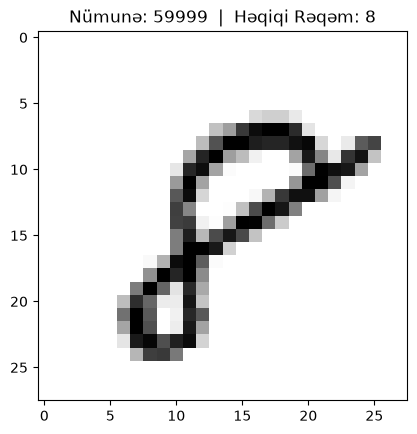

In [8]:
# İstənilən indeksdəki nümunəni və onun etiketini göstərən köməkçi funksiya
def display_sample(num):
    # Bu nümunənin həqiqi etiketi (hansı rəqəm olduğu)
    label = y_train[num] 
    
    # 784 ölçülü vektoru təkrar 28x28 ölçülü şəklə qaytarırıq ki, ekranda çəkə bilək
    image = x_train[num].reshape([28, 28])
    plt.title('Nümunə: %d  |  Həqiqi Rəqəm: %d' % (num, label))
    plt.imshow(image, cmap=plt.get_cmap('gray_r'))
    plt.show()
    
# Məsələn, 60,000-ci şəkli ekranda nümayiş etdiririk
display_sample(59999)

Gördüyünüz kimi, 60,000-ci şəklin həqiqi etiketi və görüntüsü əks olunur. Bəzi insanların əlyazması o qədər qəribə və əyridir ki, hətta insan gözü belə onun hansı rəqəm olduğunu anlamaqda çətinlik çəkə bilər!

İstəsəniz yuxarıdakı `display_sample(59999)` kodunda rəqəmi dəyişərək (məsələn, 0 ilə 59999 arasında) müxtəlif əlyazma nümunələrini araşdıra bilərsiniz.

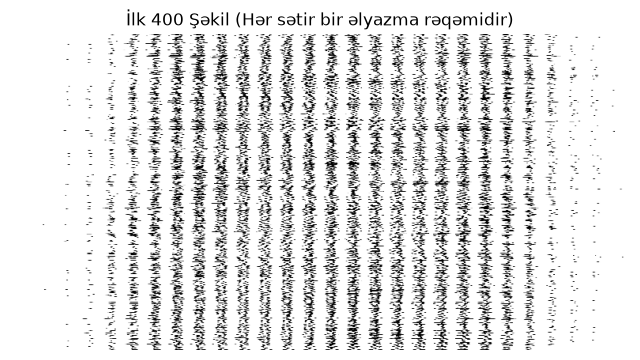

In [9]:
# İlk 400 təlim nümunəsini alt-alta düzüb böyük bir matris kimi göstəririk
# Hər bir sətir 1 ədəd şəkli (784 pikseli) təmsil edir
images = x_train[0].reshape([1, 784])
for i in range(1, 400):
    images = np.concatenate((images, x_train[i].reshape([1, 784])))

plt.figure(figsize=(8, 8))
plt.imshow(images, cmap=plt.get_cmap('gray_r'))
plt.title("İlk 400 Şəkil (Hər sətir bir əlyazma rəqəmidir)")
plt.axis('off')
plt.show()

Yuxarıdakı qrafikdə ilk 500 təlim nümunəsi alt-alta göstərilmişdir (hər sətir 1 şəkildir). Neyron şəbəkəmizi təlim edərkən hər sətirdəki 784 piksel modelin 784 giriş neyronuna ötürüləcək.

İndi isə təlimin əsas **Hiperparametrlərini (Hyperparameters)** təyin edək və verilənləri effektiv şəkildə modelə ötürmək üçün `tf.data` API-dən istifadə edək:

* 🎯 **`learning_rate` ($\alpha = 0.001$):** Qradiyent enişində addımın böyüklüyü.
* 🔄 **`training_steps` ($3000$):** Modelin neçə optimizasiya addımı atacağı.
* 📦 **`batch_size` ($250$):** Hər addımda şəbəkəyə eyni anda verilən şəkillərin sayı (Mini-batch).
* 🧠 **`n_hidden` ($512$):** Gizli qatdakı (hidden layer) neyronların sayı.

In [10]:
# Təlim parametrləri (Hiperparametrlər)
learning_rate = 0.001  # Təlim sürəti (addım ölçüsü)
training_steps = 3000  # Cəmi optimizasiya addımlarının sayı
batch_size = 250       # Hər partiyada baxılan nümunə sayı
display_step = 100     # Hər 100 addımdan bir nəticələri çap et

# Neyron şəbəkəsinin parametrləri
n_hidden = 512         # Gizli qatdakı neyronların sayı

In [11]:
# tf.data API vasitəsilə məlumatı qarışdırırıq (shuffle) və partiyalara (batch) ayırırıq
train_data = tf.data.Dataset.from_tensor_slices((x_train, y_train))

# .repeat()   -> Təlim addımları bitənə qədər datanı təkrar dövr etdirir
# .shuffle()  -> Nümunələrin ardıcıllığını qarışdırır (əzbərləmənin qarşısını almaq üçün)
# .batch()    -> Hər addım üçün 250 ədədlik partiyalara bölür
# .prefetch() -> Növbəti partiyanı yaddaşda əvvəlcədən hazır saxlayır (sürətləndirmə üçün)
train_data = train_data.repeat().shuffle(60000).batch(batch_size).prefetch(1)

## 🧠 Neyron Şəbəkəsinin Qurulması: Çəkilər ($W$) və Biaslar ($b$)

Süni neyron şəbəkəmizi sıfırdan quraq! İlk olaraq qatlar arasındakı çəkiləri və biasları saxlayacaq dəyişənləri (`tf.Variable`) yaratmalıyıq:

```
[GİRİŞ QATI]          [GİZLİ QAT]             [ÇIXIŞ QATI]
  784 piksel   --->   512 Neyron       --->    10 Rəqəm (0-9)
(num_features)        (n_hidden)              (num_classes)
              W['h']              W['out']
             (784x512)           (512x10)
```

1. **Giriş Qatı:** 784 düyün (hər piksel üçün 1 ədəd).
2. **Gizli Qat:** 512 neyron. Hər neyron 784 girişin hamısına qoşulur. Çəki matrisinin ölçüsü: $[784, 512]$, bias sayı: $512$.
3. **Çıxış Qatı:** 10 neyron (0-dan 9-a qədər rəqəmlər). Çəki matrisinin ölçüsü: $[512, 10]$, bias sayı: $10$.

> ⚠️ **Niyə çəkiləri təsadüfi (Random Normal) paylayırıq?**  
> Əgər bütün çəkiləri 0 və ya eyni ədəd etsəydik, bütün neyronlar eyni siqnalı alar və eyni şeyi öyrənərdi (Simmetriya problemi). Təsadüfi kiçik ədədlər verməklə bu simmetriyanı qırırıq və hər neyronun fərqli xüsusiyyətlər (bucağı, xətti, qövsü) öyrənməsinə şərait yaradırıq!

In [12]:
# Qatların Çəkilərini (Weights) və Biaslarını təyin edirik

# Çəkiləri ilkin olaraq normal təsadüfi paylanma ilə dolduran generator
random_normal = tf.initializers.RandomNormal()

# Çəkilər lüğəti
weights = {
    # Giriş qatından gizli qata keçid: [784, 512]
    'h': tf.Variable(random_normal([num_features, n_hidden])),
    # Gizli qatdan çıxış qatına keçid: [512, 10]
    'out': tf.Variable(random_normal([n_hidden, num_classes]))
}

# Biaslar lüğəti (başlanğıcda hamısı sıfır olaraq götürülür)
biases = {
    # Gizli qat üçün 512 ədəd bias
    'b': tf.Variable(tf.zeros([n_hidden])),
    # Çıxış qatı üçün 10 ədəd bias
    'out': tf.Variable(tf.zeros([num_classes]))
}

## ⚡ İrəli Yayılma Funksiyası (Forward Pass: `neural_net`)

İndi modelin məlumatı qəbul edib proqnoz formalaşdıran mexanizmini yazaq. Hər bir qatda ardıcıl iki əsas əməliyyat aparılır:

1. **Xətti Hesablama ($z = X \cdot W + b$):** Giriş verilənləri çəkilərlə matris vurması edilir və üzərinə bias əlavə olunur.
2. **Qeyri-xətti Aktivasiya:** Gizli qatda `tf.nn.sigmoid` istifadə olunur ki, model mürəkkəb qeyri-xətti asılılıqları öyrənə bilsin.
3. **Çıxış Qatı və Softmax:** Çıxış qatında alınan xam qiymətlər (logitlər) `tf.nn.softmax` funksiyasından keçirilir. Softmax bu logitləri cəmi $1.0$ (və ya $100\%$) olan ehtimal paylanmasına çevirir (məsələn: 0-a $2\%$, 1-ə $1\%$, 7-yə $95\%$ və s.).

In [13]:
# Modeli (İrəli Yayılma funksiyasını) təyin edirik
def neural_net(inputData):
    # 1. Gizli qat: xətti kombinasiya (X * W_h + b)
    hidden_layer = tf.add(tf.matmul(inputData, weights['h']), biases['b'])
    
    # Qeyri-xətti aktivasiya üçün Sigmoid funksiyasını tətbiq edirik
    hidden_layer = tf.nn.sigmoid(hidden_layer)
    
    # 2. Çıxış qatı: hər sinif (0-9) üçün bir xam dəyər (logit) hesablayırıq
    out_layer = tf.matmul(hidden_layer, weights['out']) + biases['out']
    
    # Logitləri ehtimal paylanmasına (0 ilə 1 arasında, cəmi 1) çevirmək üçün Softmax tətbiq edirik
    return tf.nn.softmax(out_layer)

## 🎯 İtki Funksiyası: Çarpaz Entropiya (Cross-Entropy Loss)

Modelin proqnozunun nə dərəcədə doğru və ya yanlış olduğunu ölçmək üçün **Cross-Entropy (Çarpaz Entropiya)** itki funksiyasından istifadə edirik:

$$\text{Loss} = - \sum_{i} y_{\text{true}, i} \cdot \log(y_{\text{pred}, i})$$

### 🔑 Bu Funksiya Necə İşləyir?
* **One-Hot Encoding:** Həqiqi etiketləri (məsələn, $3$ rəqəmi) 10 ölçülü vektora çeviririk: `[0, 0, 0, 1, 0, 0, 0, 0, 0, 0]` (yalnız 3-cü indeks 1-dir, qalanları 0).
* **Cəza Məntiqi:** 
  * Əgər həqiqi rəqəm $3$-dürsə və model $3$ üçün $0.99$ ehtimal veribsə: $-\log(0.99) \approx 0.01$ (Xəta demək olar ki, yoxdur).
  * Əgər model böyük əminliklə səhv edib $3$ üçün $0.01$ ehtimal veribsə: $-\log(0.01) \approx 4.6$ (Çox böyük cəza kəsilir!).
* **`clip_by_value` Nə Üçündür?** Əgər modelin proqnozu sıfır ($0.0$) olarsa, $\log(0)$ riyazi olaraq sonsuzluq (və ya `NaN`) verər və proqramı çökdürər. Bunun qarşısını almaq üçün ehtimalları minimum $10^{-9}$ həddində saxlayırıq.

In [14]:
def cross_entropy(y_pred, y_true):
    # Həqiqi tam ədəd etiketlərini one-hot vektoruna çeviririk (məs: 3 -> [0,0,0,1,0,0,0,0,0,0])
    y_true = tf.one_hot(y_true, depth=num_classes)
    
    # log(0) riyazi xətasının (NaN) qarşısını almaq üçün qiymətləri [1e-9, 1.0] aralığında saxlayırıq
    y_pred = tf.clip_by_value(y_pred, 1e-9, 1.)
    
    # Çarpaz entropiya düsturunu hesablayırıq və partiya üzrə orta xətanı tapırıq
    return tf.reduce_mean(-tf.reduce_sum(y_true * tf.math.log(y_pred)))

## ⚙️ Optimizator və Avtomatik Qradiyent: `tf.GradientTape`

Modelin xətasını ($Loss$) minimuma endirmək üçün **Stochastic Gradient Descent (SGD)** optimizatorundan istifadə edirik.

### 🌟 TensorFlow 2-nin Ən Möcüzəvi Aləti: `tf.GradientTape`
Klassik dərin öyrənmədə zəncir qaydası ilə törəmələri əllə hesablamaq olduqca zəhmətlidir. TensorFlow 2-də:
1. `with tf.GradientTape() as g:` bloku daxilində baş verən bütün irəli hesablamalar (proqnoz və loss) avtomatik lentə yazılır.
2. `g.gradient(loss, trainable_variables)` çağırıldıqda, bu lent tərsinə oxunur və hər bir çəkiyə düşən qradiyent ($\frac{\partial \text{Loss}}{\partial W}$) anında hesablanır (**Backpropagation**).
3. `optimizer.apply_gradients(...)` həmin qradiyentlər əsasında çəkiləri düzəldir:
   $$W_{\text{yeni}} = W_{\text{köhnə}} - \alpha \cdot \frac{\partial \text{Loss}}{\partial W}$$

In [15]:
# SGD (Stoxastik Qradiyent Enişi) optimizatorunu təyin edirik
optimizer = tf.keras.optimizers.SGD(learning_rate)

def run_optimization(x, y):
    # Avtomatik törəmə (Geri Yayılma) üçün hesablamaları GradientTape daxilinə alırıq
    with tf.GradientTape() as g:
        pred = neural_net(x)        # İrəli yayılma (proqnoz)
        loss = cross_entropy(pred, y) # Xətanın hesablanması
        
    # Yenilənəcək parametrlər: şəbəkənin bütün çəkiləri və biasları
    trainable_variables = list(weights.values()) + list(biases.values())

    # Geri Yayılma: Xətanın hər bir parametrə görə qradiyentini (törəməsini) hesablayırıq
    gradients = g.gradient(loss, trainable_variables)
    
    # Çəkiləri və biasları tapılan qradiyentlər istiqamətində yeniləyirik
    optimizer.apply_gradients(zip(gradients, trainable_variables))

## 📈 Modelin Dəqiqliyini (Accuracy) Necə Ölçürük?

Model 10 ədəd ehtimal çıxarır (hər rəqəm üçün bir ehtimal). Modelin yekun qərarını necə təyin edirik?
* `tf.argmax(y_pred, 1)`: Çıxış vektorundakı ən yüksək ehtimala sahib indeksin nömrəsini (təxmin edilən rəqəmi) tapır.
* `tf.equal(...)`: Təxmin edilən rəqəmlə həqiqi etiketi müqayisə edir (düzdürsə `True`, səhvdirsə `False`).
* `tf.reduce_mean(...)`: Bütün düzgün cavabların nisbətini (dəqiqlik faizini) hesablayır (məsələn, $0.93 = 93\%$).

In [16]:
# Dəqiqlik (Accuracy) metrikası
def accuracy(y_pred, y_true):
    # Ən yüksək ehtimala malik olan indeksi tapırıq (modelin qəti təxmini)
    correct_prediction = tf.equal(tf.argmax(y_pred, 1), tf.cast(y_true, tf.int64))
    
    # Düzgün cavabların (1.0) və səhvlərin (0.0) orta qiymətini taparaq ümumi faizi hesablayırıq
    return tf.reduce_mean(tf.cast(correct_prediction, tf.float32), axis=-1)

## 🏃‍♂️ Modeli Təlim Edirik (Training Loop)

İndi bütün hissələri birləşdirib təlim prosesini işə salaq!

* **3000 addım (step)** ərzində hər addımda `train_data`-dan **250 şəkillik** partiya götürülür.
* `run_optimization(batch_x, batch_y)` funksiyası çağırılaraq hər partiyada çəkilər təkmilləşdirilir.
* Hər **100 addımdan bir** cari partiya üzrə Xəta ($Loss$) və Dəqiqlik ($Accuracy$) çap olunur.

Diqqət yetirin: addımlar artdıqca xəta sürətlə azalacaq, dəqiqlik isə addım-addım yüksələcək!

In [17]:
# Təyin olunmuş addım sayı (3000) qədər təlim dövrünü işə salırıq
for step, (batch_x, batch_y) in enumerate(train_data.take(training_steps), 1):
    # Optimizasiya funksiyasını çağıraraq W və b dəyərlərini yeniləyirik
    run_optimization(batch_x, batch_y)
    
    # Hər 100 addımdan bir nəticələri ekrana çıxarırıq
    if step % display_step == 0:
        pred = neural_net(batch_x)
        loss = cross_entropy(pred, batch_y)
        acc = accuracy(pred, batch_y)
        print("Təlim addımı: %i | Xəta (Loss): %f | Dəqiqlik (Accuracy): %f" % (step, loss, acc))

Təlim addımı: 100 | Xəta (Loss): 166.303574 | Dəqiqlik (Accuracy): 0.844000
Təlim addımı: 200 | Xəta (Loss): 114.788925 | Dəqiqlik (Accuracy): 0.872000
Təlim addımı: 300 | Xəta (Loss): 114.096092 | Dəqiqlik (Accuracy): 0.884000
Təlim addımı: 400 | Xəta (Loss): 105.150085 | Dəqiqlik (Accuracy): 0.880000
Təlim addımı: 500 | Xəta (Loss): 81.010551 | Dəqiqlik (Accuracy): 0.916000
Təlim addımı: 600 | Xəta (Loss): 69.567551 | Dəqiqlik (Accuracy): 0.936000
Təlim addımı: 700 | Xəta (Loss): 81.506927 | Dəqiqlik (Accuracy): 0.904000
Təlim addımı: 800 | Xəta (Loss): 87.858047 | Dəqiqlik (Accuracy): 0.920000
Təlim addımı: 900 | Xəta (Loss): 63.759354 | Dəqiqlik (Accuracy): 0.928000
Təlim addımı: 1000 | Xəta (Loss): 64.236458 | Dəqiqlik (Accuracy): 0.916000
Təlim addımı: 1100 | Xəta (Loss): 87.083488 | Dəqiqlik (Accuracy): 0.908000
Təlim addımı: 1200 | Xəta (Loss): 67.539192 | Dəqiqlik (Accuracy): 0.924000
Təlim addımı: 1300 | Xəta (Loss): 74.960892 | Dəqiqlik (Accuracy): 0.904000
Təlim addımı: 140

In [18]:
# Modeli heç vaxt görmədiyi Test dəstində yoxlayırıq
pred = neural_net(x_test)
print("Test Dəsti Üzrə Yekun Dəqiqlik: %f" % accuracy(pred, y_test))

Test Dəsti Üzrə Yekun Dəqiqlik: 0.931000


Model təlimdə heç vaxt görmədiyi test şəkillərində təxminən **93% dəqiqlik** göstərdi! Sadə bir çoxqatlı perseptron (MLP) üçün bu olduqca yaxşı nəticədir.

---

## 🔎 Model Harada Səhv Etdi? (Səhv Tanınan Şəkillərin Təhlili)

Gəlin ilk 200 test şəklini araşdıraq və modelin hansı şəkillərdə yanıldığını, həqiqi etiketin nə olduğunu və modelin nə dediyini öz gözlərimizlə görək:

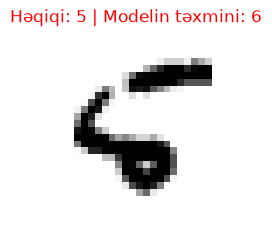

Şəkil nömrəsi: 8
Həqiqi Etiket (Original Label): 5
Modelin Təxmini (Model Prediction): 6
----------------------------------------


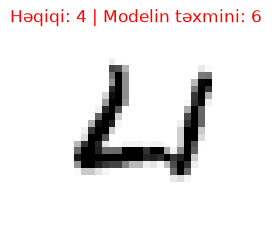

Şəkil nömrəsi: 33
Həqiqi Etiket (Original Label): 4
Modelin Təxmini (Model Prediction): 6
----------------------------------------


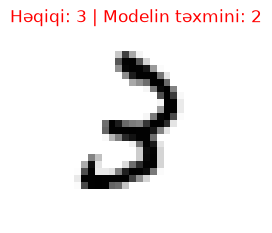

Şəkil nömrəsi: 63
Həqiqi Etiket (Original Label): 3
Modelin Təxmini (Model Prediction): 2
----------------------------------------


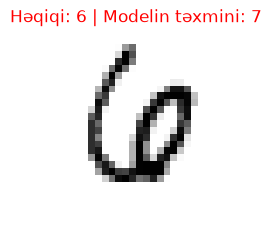

Şəkil nömrəsi: 66
Həqiqi Etiket (Original Label): 6
Modelin Təxmini (Model Prediction): 7
----------------------------------------


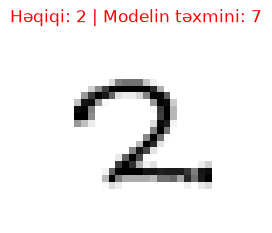

Şəkil nömrəsi: 77
Həqiqi Etiket (Original Label): 2
Modelin Təxmini (Model Prediction): 7
----------------------------------------


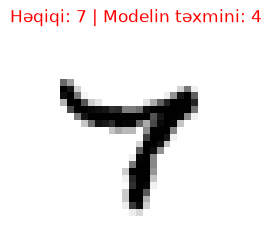

Şəkil nömrəsi: 124
Həqiqi Etiket (Original Label): 7
Modelin Təxmini (Model Prediction): 4
----------------------------------------


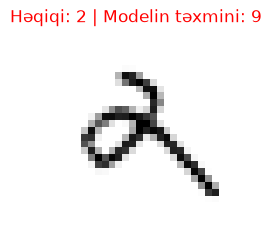

Şəkil nömrəsi: 149
Həqiqi Etiket (Original Label): 2
Modelin Təxmini (Model Prediction): 9
----------------------------------------


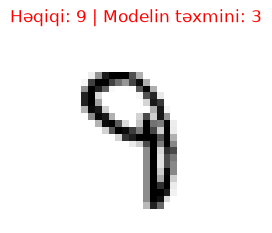

Şəkil nömrəsi: 193
Həqiqi Etiket (Original Label): 9
Modelin Təxmini (Model Prediction): 3
----------------------------------------


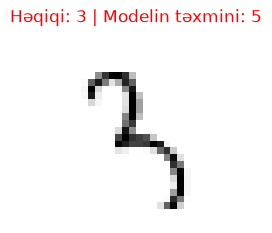

Şəkil nömrəsi: 195
Həqiqi Etiket (Original Label): 3
Modelin Təxmini (Model Prediction): 5
----------------------------------------


In [19]:
n_images = 200
test_images = x_test[:n_images]
test_labels = y_test[:n_images]
predictions = neural_net(test_images)

# Yanlış proqnoz verilən şəkilləri tapıb ekranda göstəririk
for i in range(n_images):
    model_prediction = np.argmax(predictions.numpy()[i])
    if (model_prediction != test_labels[i]):
        plt.figure(figsize=(2.5, 2.5))
        plt.imshow(np.reshape(test_images[i], [28, 28]), cmap='gray_r')
        plt.title("Həqiqi: %i | Modelin təxmini: %i" % (test_labels[i], model_prediction), color='red')
        plt.axis('off')
        plt.show()
        print("Şəkil nömrəsi: %i" % i)
        print("Həqiqi Etiket (Original Label): %i" % test_labels[i])
        print("Modelin Təxmini (Model Prediction): %i" % model_prediction)
        print("-" * 40)